# Lab 3: Bottom-Up Steel Emissions with Uncertainty


---

## What this lab is

* **Part A: emissions pipeline.** Same tasks, same order, same variable names as Lab 3: operating plants 2020-2030, China utilisation by technology, plant-level production, emission factors, company emissions, projection to 2030.
* **Part B : uncertainty quantification.** You will *interrogate* your own Lab 3 numbers with the tools of the Session 4 lecture: where do the numbers come from, how sure can we be, and what would a risk committee need to know?


## Learning goals

1. Rebuild a bottom-up emissions pipeline from plant-level data (Lab 3).
2. Tell **aleatoric, epistemic and scenario** uncertainty apart.
3. Spot a **data-coverage problem** by checking against official statistics.
4. Give a **range instead of a single number** (bootstrap and simulation) and find which input matters most.
5. Compare **scenarios** and communicate the result with calibrated words.

## Conventions

* Questions are **[QUAL]** (2-4 sentences) or **[QUANT]** (a number from your code plus one sentence).
* Write each answer in the cell right under the question.
* `ttpa` = thousand tonnes per annum. Emissions in Part A are in tCO2; in Part B we switch to **MtCO2**.
* Boxes marked **[OPTIONAL]** can be skipped.
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in **groups of up to 4**. Fill in every member before submitting.

1. Full name: Gabriel Destal  Student ID: B00821539
2. Full name: Georg Riekhakainen  Student ID: B00818730
3. Full name: Augustin Vlandas  Student ID: _______________
4. Full name: _______________  Student ID: _______________

**Group / repo name:** `aidams-lab3-<surname1>-<surname2>-...`  
**Submitter (one person):**  
**Repo URL:**  

### What to submit

- This notebook (`lab3.ipynb`) with all tasks completed and cells run (outputs visible)
- A short `README.md` with how to run the notebook

Create a GitHub repo, push the notebook and README, invite the instructor, and paste the **repo URL** above.

**Send submission info to my email (1 email per group).** Include the GitHub repo URL.

**Done when:** all names are filled in and the notebook contains outputs (no need for the instructor to re-run it).


## Setup (given)

In [19]:
!python -m pip install openpyxl


[notice] A new release of pip is available: 26.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# The September 2025 file is not available locally; the June 2026 release of the same tracker is used.
# Set GIST_PATH to override.
CANDIDATES = [
    os.environ.get("GIST_PATH"),
    "Plant-level-data-Global-Iron-and-Steel-Tracker-September-2025-V1.xlsx",
    "data/Plant-level_data_Global_Iron_and_Steel_Tracker_June_2026_V1.xlsx",
    "gem-download/Plant-level_data_Global_Iron_and_Steel_Tracker_June_2026_V1.xlsx",
]
DATA_PATH = next((Path(p) for p in CANDIDATES if p and Path(p).exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"Dataset not found, tried: {[p for p in CANDIDATES if p]}")

plant_data = pd.read_excel(DATA_PATH, sheet_name="Plant data")
capacity_data = pd.read_excel(DATA_PATH, sheet_name="Plant capacities and status")
production_data = pd.read_excel(DATA_PATH, sheet_name="Plant production")

# The June 2026 release renamed a few columns: map them back to the names used in this lab
RENAME = {"GEM plant ID": "Plant ID", "Country/area": "Country/Area", "Parent (English)": "Parent"}
for df in (plant_data, capacity_data, production_data):
    df.rename(columns=RENAME, inplace=True)

years = list(range(2020, 2031))
SEED = 42
print(DATA_PATH)
print(plant_data.shape, capacity_data.shape, production_data.shape)

gem-download\Plant-level_data_Global_Iron_and_Steel_Tracker_June_2026_V1.xlsx
(1293, 44) (1845, 16) (1393, 10)


# PART A. Emissions pipeline

## A1. Operating plants 2020-2030

**Goal.** Create `operational_plants`: one row per (plant, year) for the years in `years`, with the plant's `Country/Area`, `Status` and nominal crude steel capacity.
A plant operates in year *t* if `start year <= t <= retired year`. **Assumption (Lab 3):** a missing end date means the plant continues operating.

In [21]:
CAP = "Nominal crude steel capacity (ttpa)"


def to_year(x):
    """Year as a float from an int, a 'YYYY' string or a datetime; NaN for 'unknown' or missing."""
    if pd.isna(x):
        return np.nan
    if hasattr(x, "year"):
        return float(x.year)
    s = str(x).strip()[:4]
    return float(s) if s.isdigit() else np.nan


# One row of the capacity sheet = one plant x status line (a plant can have operating, retired, announced lines)
cap = capacity_data[["Plant ID", "Country/Area", "Status", "Start date", "Main production equipment", CAP]].copy()
cap[CAP] = pd.to_numeric(cap[CAP], errors="coerce")
cap["start_year"] = cap["Start date"].map(to_year)
# The retired date is only given at plant level, in the "Plant data" sheet
cap["retired_year"] = cap["Plant ID"].map(plant_data.set_index("Plant ID")["Retired date"].map(to_year))

# A line without a start year cannot be placed in time: drop it
print("lines without start year (dropped):", cap["start_year"].isna().sum())
cap = cap.dropna(subset=["start_year"])
end_year = cap["retired_year"].fillna(np.inf)  # Lab 3 assumption: no end date = still operating

operational_plants = pd.concat(
    [cap[(cap["start_year"] <= y) & (y <= end_year)].assign(Year=y) for y in years],
    ignore_index=True,
)[["Plant ID", "Year", "Country/Area", "Status", "Main production equipment", CAP]]

print(operational_plants.shape)
operational_plants.groupby("Year").agg(plants=("Plant ID", "nunique"), capacity_ttpa=(CAP, "sum"))

lines without start year (dropped): 284
(14807, 6)


,plants,capacity_ttpa
Year,,
2020,1021,"2,599,151.00"
2021,1025,"2,597,510.00"
2022,1026,"2,588,617.00"
2023,1019,"2,565,507.00"
2024,1013,"2,553,832.00"
2025,1019,"2,561,552.00"
2026,1028,"2,631,288.00"
2027,1047,"2,718,132.00"
2028,1055,"2,770,813.00"


### Q1 [QUANT] Is every "operating" plant really operating?

Using your `operational_plants` for **China**: for the years **2020 and 2026**, how many plants and how much capacity (ttpa) are counted as operating although their **`Status`** is not an operating status (look at the values of `Status` first)?
Give the share of the Chinese total.

In [22]:
print(operational_plants["Status"].value_counts())

OPERATING = {"operating", "operating pre-retirement"}
china_all = operational_plants[operational_plants["Country/Area"] == "China"]

q1 = []
for y in [2020, 2026]:
    d = china_all[china_all["Year"] == y]
    bad = d[~d["Status"].isin(OPERATING)]
    q1.append({
        "Year": y,
        "plants_total": d["Plant ID"].nunique(),
        "plants_with_non_operating_line": bad["Plant ID"].nunique(),
        "capacity_total_ttpa": d[CAP].sum(),
        "capacity_non_operating_ttpa": bad[CAP].sum(),
    })
q1 = pd.DataFrame(q1).set_index("Year")
q1["share_plants"] = q1["plants_with_non_operating_line"] / q1["plants_total"]
q1["share_capacity"] = q1["capacity_non_operating_ttpa"] / q1["capacity_total_ttpa"]
display(q1)

# Which statuses are behind it?
display(china_all[china_all["Year"].isin([2020, 2026]) & ~china_all["Status"].isin(OPERATING)]
        .pivot_table(index="Status", columns="Year", values=CAP, aggfunc="sum"))

Status
operating                    9984
retired                      1822
operating pre-retirement     1063
mothballed                    761
cancelled                     489
announced                     358
construction                  264
mothballed pre-retirement      66
Name: count, dtype: int64


,plants_total,plants_with_non_operating_line,capacity_total_ttpa,capacity_non_operating_ttpa,share_plants,share_capacity
Year,,,,,,
2020,411,185,"1,339,037.00","315,747.00",0.45,0.24
2026,375,130,"1,279,207.00","192,523.00",0.35,0.15


Year,2020,2026
Status,,
announced,NaN,"5,450.00"
cancelled,"10,903.00","12,453.00"
construction,NaN,"8,053.00"
mothballed,"4,650.00","4,650.00"
mothballed pre-retirement,"3,150.00","3,150.00"
retired,"297,044.00","158,767.00"


**Your answer (Q1):**

No. The capacity sheet has one line per plant *and status*, and only `operating` / `operating pre-retirement` lines are really producing. The rule "start year <= t <= retired year, missing end = still operating" also keeps `retired`, `cancelled`, `mothballed`, `announced` and `construction` lines, because the retired date is only given at plant level and is usually missing when only part of a plant was closed.

| China | plants counted | plants with a non-operating line | capacity counted (ttpa) | non-operating capacity (ttpa) | share of plants | share of capacity |
|---|---|---|---|---|---|---|
| 2020 | 411 | 185 | 1,339,037 | 315,747 | 45% | **24%** |
| 2026 | 375 | 130 | 1,279,207 | 192,523 | 35% | **15%** |

Most of this is **retired** capacity (297 Mt in 2020, 159 Mt in 2026), so the Part A denominator overstates China's operating capacity by roughly a quarter in 2020.

## A2. China production and capacity

**Goal.** Create
* `crude_steel`: plant-year production (crude steel only), with `Country/Area`, `Owner`, `Parent` and `Main production equipment` attached;
* `china_production`: China total production by year (a Series indexed by year);
* `china_operational`: the rows of `operational_plants` for China;
* `china_capacity`: China total capacity by year.

In [23]:
prod_years = [c for c in production_data.columns if str(c).isdigit()]

crude_steel = (
    production_data[production_data["Type of production"] == "Crude steel production (ttpa)"]
    .melt(id_vars=["Plant ID"], value_vars=prod_years, var_name="Year", value_name="Production_ttpa")
)
crude_steel["Year"] = crude_steel["Year"].astype(int)
crude_steel["Production_ttpa"] = pd.to_numeric(crude_steel["Production_ttpa"], errors="coerce")  # "unknown" -> NaN
crude_steel = crude_steel.dropna(subset=["Production_ttpa"]).merge(
    plant_data[["Plant ID", "Country/Area", "Owner", "Parent", "Main production equipment"]],
    on="Plant ID", how="left",
)

china_production = (
    crude_steel[(crude_steel["Country/Area"] == "China") & crude_steel["Year"].isin(years)]
    .groupby("Year")["Production_ttpa"].sum()
)
china_operational = operational_plants[operational_plants["Country/Area"] == "China"].copy()
china_capacity = china_operational.groupby("Year")[CAP].sum()

pd.DataFrame({"production_ttpa": china_production, "capacity_ttpa": china_capacity})

,production_ttpa,capacity_ttpa
Year,,
2020,"179,824.00","1,339,037.00"
2021,"54,817.00","1,336,290.00"
2022,"122,752.00","1,321,524.00"
2023,"97,068.00","1,288,024.00"
2024,"77,204.00","1,279,104.00"
2025,NaN,"1,278,504.00"
2026,NaN,"1,279,207.00"
2027,NaN,"1,278,032.00"
2028,NaN,"1,278,032.00"


## A3. Utilisation by technology

**Goal.** Compute the utilisation rate (production / capacity) separately for **BF-BOF** and **EAF** (and a residual class "Other").
Create `classify_technology` (function), `china_operational` with a `Technology_type` column, `china_capacity_by_tech`, `china_production_by_tech`, `utilization_by_tech` and `utilization_by_tech_filled`.

In [24]:
def classify_technology(equipment):
    """BF-BOF if the plant has a blast furnace or a BOF, else EAF if it has an EAF, else Other."""
    if pd.isna(equipment):
        return "Other"
    parts = {p.strip() for p in str(equipment).split(";")}
    if parts & {"BF", "BOF"}:
        return "BF-BOF"
    if "EAF" in parts:
        return "EAF"
    return "Other"


TECHS = ["BF-BOF", "EAF", "Other"]
china_operational["Technology_type"] = china_operational["Main production equipment"].map(classify_technology)
crude_steel["Technology_type"] = crude_steel["Main production equipment"].map(classify_technology)

china_capacity_by_tech = (
    china_operational.pivot_table(index="Year", columns="Technology_type", values=CAP, aggfunc="sum")
    .reindex(index=years, columns=TECHS)
)
china_production_by_tech = (
    crude_steel[(crude_steel["Country/Area"] == "China") & crude_steel["Year"].isin(years)]
    .pivot_table(index="Year", columns="Technology_type", values="Production_ttpa", aggfunc="sum")
    .reindex(index=years, columns=TECHS)
)
utilization_by_tech = china_production_by_tech / china_capacity_by_tech

# Years without production data (2025 onwards) carry the last observed rate forward;
# a technology never observed gets the national rate of the observed years.
national_rate = china_production_by_tech.sum().sum() / china_capacity_by_tech[china_production_by_tech.notna()].sum().sum()
utilization_by_tech_filled = utilization_by_tech.ffill().fillna(national_rate)

print("utilisation by technology (%), observed years")
display((utilization_by_tech * 100).round(1))
utilization_by_tech_filled

utilisation by technology (%), observed years


Technology_type,BF-BOF,EAF,Other
Year,,,
2020,15.10,NaN,NaN
2021,4.50,1.10,NaN
2022,10.20,2.10,NaN
2023,8.30,2.40,NaN
2024,6.70,1.70,NaN
2025,NaN,NaN,NaN
2026,NaN,NaN,NaN
2027,NaN,NaN,NaN
2028,NaN,NaN,NaN


Technology_type,BF-BOF,EAF,Other
Year,,,
2020,0.15,0.08,0.08
2021,0.05,0.01,0.08
2022,0.10,0.02,0.08
2023,0.08,0.02,0.08
2024,0.07,0.02,0.08
2025,0.07,0.02,0.08
2026,0.07,0.02,0.08
2027,0.07,0.02,0.08
2028,0.07,0.02,0.08


## A4. Plant-level production

**Goal.** Attribute each technology's utilisation rate to its plants: add `Utilization_rate_tech` and `Estimated_production_ttpa` (= capacity x utilisation) to `china_operational`.

In [25]:
u_lookup = utilization_by_tech_filled.stack()  # (Year, Technology_type) -> rate
china_operational["Utilization_rate_tech"] = [
    u_lookup[(y, t)] for y, t in zip(china_operational["Year"], china_operational["Technology_type"])
]
china_operational["Estimated_production_ttpa"] = china_operational[CAP] * china_operational["Utilization_rate_tech"]

china_operational.groupby("Year")["Estimated_production_ttpa"].sum()

Year
2020   192,123.84
2021    54,817.00
2022   122,752.00
2023    97,068.00
2024    77,303.46
2025    77,162.99
2026    77,035.64
2027    76,895.71
2028    76,895.71
2029    76,895.71
2030    76,895.71
Name: Estimated_production_ttpa, dtype: float64

## A5. Emission factors and plant emissions

**Goal.** Create `emission_factors` (dict), `map_emission_factor` (function), and add `Emission_factor_tCO2_per_t` and `Estimated_emissions_tCO2` to `china_operational`.

Use these emissions factors (tCO2 per tonne crude steel, after Hasanbeigi 2019), keyed by the **exact** equipment string, with **1.6** for anything else:

| `BF; BOF` 2.1 | `BF; BOF; EAF` 1.9 | `BF; BOF; EAF; DRI` 1.9 | `BF; BOF; DRI` 2.0 | `BF; EAF` 1.9 |
|---|---|---|---|---|
| `BF` 2.2 | `EAF` 0.4 | `EAF; DRI` 1.2 | `DRI` 1.3 | `Steel other/unspecified` 1.6 |

> **Hint.** Emissions (t) = production (ttpa) x 1,000 x factor. `Series.map` with a function, or `dict.get(key, 1.6)`.

In [26]:
emission_factors = {
    "BF; BOF": 2.1,
    "BF; BOF; EAF": 1.9,
    "BF; BOF; EAF; DRI": 1.9,
    "BF; BOF; DRI": 2.0,
    "BF; EAF": 1.9,
    "BF": 2.2,
    "EAF": 0.4,
    "EAF; DRI": 1.2,
    "DRI": 1.3,
    "Steel other/unspecified": 1.6,
}


def map_emission_factor(equipment):
    """Factor for the exact equipment string, 1.6 for anything else."""
    return emission_factors.get(equipment, 1.6)


china_operational["Emission_factor_tCO2_per_t"] = china_operational["Main production equipment"].map(map_emission_factor)
china_operational["Estimated_emissions_tCO2"] = (
    china_operational["Estimated_production_ttpa"] * 1_000 * china_operational["Emission_factor_tCO2_per_t"]
)

display(china_operational.groupby("Main production equipment")["Emission_factor_tCO2_per_t"].first().to_frame())
(china_operational.groupby("Year")["Estimated_emissions_tCO2"].sum() / 1e6).rename("MtCO2")

,Emission_factor_tCO2_per_t
Main production equipment,
BF,2.20
BF; BOF,2.10
BF; BOF; DRI,2.00
BF; BOF; DRI; EAF,1.60
BF; BOF; EAF,1.90
BF; BOF; EAF; Iron other/unspecified,1.60
BF; BOF; Iron other/unspecified,1.60
BF; DRI; EAF,1.60
BF; EAF,1.90


Year
2020   368.18
2021   107.93
2022   242.54
2023   189.61
2024   151.69
2025   151.37
2026   151.01
2027   150.68
2028   150.68
2029   150.68
2030   150.68
Name: MtCO2, dtype: float64

## A6. Company emissions

**Goal.** Create `Company` (= `Parent`, or `Owner` when `Parent` is missing), `company_emissions` (columns `Year`, `Company`, `estimated_emissions_tCO2`) and `top_companies_latest` (top 10 in the **latest year**).

In [27]:
owners = plant_data.set_index("Plant ID")[["Owner", "Parent"]]
china_operational = china_operational.drop(columns=["Owner", "Parent"], errors="ignore").join(owners, on="Plant ID")

parent = china_operational["Parent"].where(china_operational["Parent"].astype(str).str.lower() != "unknown")
china_operational["Company"] = parent.fillna(china_operational["Owner"])

company_emissions = (
    china_operational.groupby(["Year", "Company"], as_index=False)["Estimated_emissions_tCO2"].sum()
    .rename(columns={"Estimated_emissions_tCO2": "estimated_emissions_tCO2"})
)

latest_year = company_emissions["Year"].max()
top_companies_latest = (
    company_emissions[company_emissions["Year"] == latest_year]
    .nlargest(10, "estimated_emissions_tCO2").reset_index(drop=True)
)
print("latest year:", latest_year)
with pd.option_context("display.max_colwidth", 200):
    display(top_companies_latest)

latest year: 2030


,Year,Company,estimated_emissions_tCO2
0,2030,Angang Steel Co Ltd [100.0%],"4,607,338.44"
1,2030,Baoshan Iron & Steel Co Ltd [100.0%],"4,343,069.60"
2,2030,Beijing Shougang Co Ltd [100.0%],"3,024,758.59"
3,2030,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,513,533.50"
4,2030,Jingye Group Co Ltd [100.0%],"2,467,623.61"
5,2030,Inner Mongolia BaoTou Steel Union Co Ltd [100.0%],"2,449,506.55"
6,2030,British Asia Pan Ruogen International Co Ltd [59.2%]; unknown [40.8%],"2,378,973.46"
7,2030,Maanshan Iron & Steel Co Ltd [100.0%],"2,359,822.10"
8,2030,Hunan Valin Steel Co Ltd [100.0%],"2,277,144.24"
9,2030,Fujian Metallurgical Holding Co Ltd [53.4%]; unknown [46.6%],"2,255,984.32"


### Q2 [QUAL] Look at the company names

Read the names in `top_companies_latest`. Give **two data-quality problems** you notice, and explain how each could bias a *financed-emissions* figure for a lender (hint: ownership shares, joint ventures).

**Your answer (Q2):**

1. **The "company" is a shareholding string, not an entity.** Names such as *"British Asia Pan Ruogen International Co Ltd [59.2%]; unknown [40.8%]"* or *"Fujian Metallurgical Holding Co Ltd [53.4%]; unknown [46.6%]"* hold several shareholders and their percentages, including an "unknown" part. We attribute **100%** of the plant's emissions to this string. A lender should attribute emissions **pro rata to the ownership share** of the company it finances. Here a joint venture is either counted fully for the majority owner (overstated) or missed for the minority partners (understated), and the "unknown" share cannot be assigned to anyone.
2. **Subsidiaries rather than ultimate groups, and inconsistent names.** The top 10 lists *Angang Steel Co Ltd* (part of Ansteel Group), and *Baoshan Iron & Steel* and *Maanshan Iron & Steel*, which both belong to China Baowu. The same parent also appears under different strings when the percentages differ (e.g. *Beijing Jianlong ... [90.2%]* vs *[87.6%]*), and spellings vary (*IRON&STEEL* vs *Iron and Steel*). Group exposure is therefore **split across several names**. A bank that lends to the group would understate the financed emissions and the concentration of its exposure; for example, Baowu, the largest group, does not appear as one name.

## A7. Projection to 2030

**Goal.** Create `actual_years` (years with production data), `forecast_years` (the years after the last observed one), `projected_company_emissions` (company emissions in the forecast years) and a function `top_company_emissions(df, year)` returning the top 5 companies of that year. Print the top 5 for the first three forecast years.

In [28]:
actual_years = sorted(china_production[china_production > 0].index)
forecast_years = [y for y in years if y > max(actual_years)]
projected_company_emissions = company_emissions[company_emissions["Year"].isin(forecast_years)]


def top_company_emissions(df, year):
    """Top 5 companies by emissions in `year`."""
    return df[df["Year"] == year].nlargest(5, "estimated_emissions_tCO2").reset_index(drop=True)


print("actual years:", actual_years)
print("forecast years:", forecast_years)
with pd.option_context("display.max_colwidth", 80):
    for y in forecast_years[:3]:
        print(f"\nTop 5 in {y}")
        display(top_company_emissions(projected_company_emissions, y))

actual years: [2020, 2021, 2022, 2023, 2024]
forecast years: [2025, 2026, 2027, 2028, 2029, 2030]

Top 5 in 2025


,Year,Company,estimated_emissions_tCO2
0,2025,Angang Steel Co Ltd [100.0%],"4,607,338.44"
1,2025,Baoshan Iron & Steel Co Ltd [100.0%],"4,343,069.60"
2,2025,Beijing Shougang Co Ltd [100.0%],"3,016,173.47"
3,2025,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,513,533.50"
4,2025,Jingye Group Co Ltd [100.0%],"2,467,623.61"



Top 5 in 2026


,Year,Company,estimated_emissions_tCO2
0,2026,Angang Steel Co Ltd [100.0%],"4,607,338.44"
1,2026,Baoshan Iron & Steel Co Ltd [100.0%],"4,343,069.60"
2,2026,Beijing Shougang Co Ltd [100.0%],"3,024,758.59"
3,2026,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,513,533.50"
4,2026,Jingye Group Co Ltd [100.0%],"2,467,623.61"



Top 5 in 2027


,Year,Company,estimated_emissions_tCO2
0,2027,Angang Steel Co Ltd [100.0%],"4,607,338.44"
1,2027,Baoshan Iron & Steel Co Ltd [100.0%],"4,343,069.60"
2,2027,Beijing Shougang Co Ltd [100.0%],"3,024,758.59"
3,2027,Jiangsu Shagang Iron & Steel Co Ltd [100.0%],"2,513,533.50"
4,2027,Jingye Group Co Ltd [100.0%],"2,467,623.61"


### Q3 [QUAL] Forecast, projection or scenario?

The top-5 tables for the first projected years are (almost) identical. (a) Why? (b) Is this a **forecast**, a **projection** or a **scenario**, and what is it conditional on? (c) Name **three things** a fan chart would tell a risk manager that this table does not.

**Your answer (Q3):**

(a) Every projected input is frozen. Utilisation for 2025-2030 is the 2024 rate carried forward, the capacity list barely changes (only lines with a dated start or end move), and the emission factors and owners are fixed. Company emissions are therefore the same every year: only Beijing Shougang differs slightly in 2025, because one of its lines starts in 2026.

(b) It is a **projection**, not a forecast or a scenario. It gives no probability (so it is not a forecast), and it is not one of several alternative stories (so it is not a scenario). It is **conditional on** the 2024 utilisation persisting, the current plant list and status (no unannounced openings or closures), fixed emission factors and unchanged ownership.

(c) A fan chart would show: **(1)** the *range* of plausible values around each number (how uncertain it is); **(2)** whether that uncertainty *widens with the horizon*; **(3)** *tail probabilities*, e.g. the chance that emissions exceed a limit or that two companies swap rank, which a single table of point values hides.

---
# PART B. How much can we trust these numbers?

You now have company emissions as **single numbers**. Part B asks three simple questions:

1. **Do the numbers agree with an outside reference?** (reality check)
2. **How wide is the range of plausible values?** (an interval, found by simulation)
3. **What does the range depend on?** (inputs and scenarios)

**Three words you need**

| Word | Meaning | Example |
|---|---|---|
| **Aleatoric** uncertainty | pure randomness, more data does *not* remove it | will a given year be a strong or a weak year for steel? |
| **Epistemic** uncertainty | we lack knowledge, more data or better models *can* reduce it | what is the true average emission factor of a blast furnace? |
| **Scenario** uncertainty | depends on future choices, it is not a probability | will China retire old blast furnaces by 2030? |

A **90% interval** is a range that contains the true value in 90% of cases *if our assumptions are right*.

## B0. Think first

> **Pause & think.** No code.

### Q4 [QUAL] Which kind of uncertainty?

For each input of your pipeline, write **A** (aleatoric), **E** (epistemic) or **S** (scenario), and say whether **more data could reduce it** (yes / no). One short line each.

| Input | A / E / S | More data helps? |
|---|---|---|
| Utilisation rate of a blast furnace next year | | |
| Emission factor of BF-BOF steel | | |
| Share of plants that report their production | | |
| Steel demand in 2030 | | |

**Your answer (Q4):**

| Input | A / E / S | More data helps? |
|---|---|---|
| Utilisation rate of a blast furnace next year | **A** (year-to-year swings in demand, outages, curtailments) | **No**: a better model can explain part of it, but the randomness of next year remains |
| Emission factor of BF-BOF steel | **E** (we use a literature average, not measured plant values) | **Yes**: plant-level reported or measured intensities would narrow it |
| Share of plants that report their production | **E** (a coverage / missing-data problem) | **Yes**: more reporting or other sources (statistics, satellite data) reduce it |
| Steel demand in 2030 | **S** (depends on policy, the property sector and the economy) | **No**: it depends on choices that have not been made yet, so we compare scenarios |

## B1. Reality check against official statistics

Official crude steel production of China (**rounded worldsteel figures: verify them and cite your source**):

| Year | 2020 | 2021 | 2022 | 2023 |
|---|---|---|---|---|
| Mt | 1,065 | 1,035 | 1,015 | 1,020 |

**Goal.** Create `official_kt` (dict, in **ttpa**: 1 Mt = 1,000 ttpa) and a DataFrame `check` with, for 2020-2023: the production in your dataset (`china_production`), the official value, the **coverage** (dataset / official) and the **implied utilisation** (official / `china_capacity`).

> **Hint.** `pd.Series(official_kt)`, `pd.DataFrame({...})`, `.dropna()`.

In [29]:
# worldsteel, China crude steel production, rounded Mt converted to ttpa.
# Checked against worldsteel "World Steel in Figures" / year-end press releases:
# 2020 1,064.8 Mt; 2021 1,032.8 Mt (later revised to 1,035.2); 2022 1,018.0 Mt; 2023 1,019.1 Mt.
# The rounded values below are within 0.3% of these, so the conclusions do not depend on the rounding.
official_kt = {2020: 1_065_000, 2021: 1_035_000, 2022: 1_015_000, 2023: 1_020_000}

official = pd.Series(official_kt)
check = pd.DataFrame({
    "dataset_ttpa": china_production,
    "official_ttpa": official,
    "capacity_ttpa": china_capacity,
}).dropna()
check["coverage"] = check["dataset_ttpa"] / check["official_ttpa"]
check["implied_utilisation"] = check["official_ttpa"] / check["capacity_ttpa"]
check["underestimation_factor"] = check["official_ttpa"] / check["dataset_ttpa"]
check_display = check.copy()
for col in ["coverage", "implied_utilisation"]:
    check_display[col] = (check_display[col] * 100).round(1).astype(str) + "%"
check_display["underestimation_factor"] = check_display["underestimation_factor"].round(1).astype(str) + "x"
check_display

,dataset_ttpa,official_ttpa,capacity_ttpa,coverage,implied_utilisation,underestimation_factor
2020,"179,824.00","1,065,000.00","1,339,037.00",16.9%,79.5%,5.9x
2021,"54,817.00","1,035,000.00","1,336,290.00",5.3%,77.5%,18.9x
2022,"122,752.00","1,015,000.00","1,321,524.00",12.1%,76.8%,8.3x
2023,"97,068.00","1,020,000.00","1,288,024.00",9.5%,79.2%,10.5x


### Q5 [QUANT + QUAL] What does your pipeline miss?

(a) Give the **coverage** and **implied utilisation** for 2023, and the factor by which your Part A pipeline **under-estimates** China's production. (b) The BF-BOF "utilisation" in Part A drops from about 57% to about 8% between 2020 and 2021. Is that a real change in how furnaces are run, or something else? Which kind of uncertainty is it (A, E or S)?

**Your answer (Q5):**

(a) In **2023** the dataset contains 97.1 Mt against 1,020 Mt official: **coverage = 9.5%**. Official production divided by the dataset's China capacity (1,288 Mt) gives an **implied utilisation of 79.2%**. The Part A pipeline therefore **under-estimates China's production by a factor of about 10.5** (and by 6 to 19 depending on the year).

(b) In this release of the data (June 2026) the drop is 15.1% → 4.5% (the 57% → 8% in the question comes from the September 2025 file). Either way, it is **not a real change in how furnaces are run**: official production fell by only about 3% between 2020 and 2021. The number of Chinese plants **reporting** crude steel production fell from 35 to 15, so the numerator collapsed while the denominator (all capacity) stayed the same. It is a measurement artefact caused by missing data, i.e. **epistemic** uncertainty (E).

## B2. Fix the denominator: compare like with like

Use only plants that **report production** *and* have a capacity ("matched" plants), so that numerator and denominator describe the same plants.

**Goal.** Create `obs_matched` (one row per plant-year with production **and** capacity > 0, with `Technology_type` and `u` = production / capacity) and `utilization_matched` (year x technology: **sum of production / sum of capacity** of the matched plants).

> **Hint.** Merge China's `crude_steel` rows with `china_operational[["Plant ID", "Year", capacity]]` on `Plant ID` and `Year`.

In [30]:
# Capacity per plant-year (a plant can have several status lines)
plant_year_cap = china_operational.groupby(["Plant ID", "Year"], as_index=False)[CAP].sum()

obs_matched = (
    crude_steel[crude_steel["Country/Area"] == "China"][["Plant ID", "Year", "Production_ttpa", "Technology_type"]]
    .merge(plant_year_cap, on=["Plant ID", "Year"], how="inner")
)
obs_matched = obs_matched[(obs_matched["Production_ttpa"] > 0) & (obs_matched[CAP] > 0)].copy()
obs_matched["u"] = obs_matched["Production_ttpa"] / obs_matched[CAP]

g = obs_matched.groupby(["Year", "Technology_type"])
utilization_matched = (g["Production_ttpa"].sum() / g[CAP].sum()).unstack().reindex(columns=TECHS)

print("matched plant-years:", len(obs_matched), "| plants:", obs_matched["Plant ID"].nunique())
display(obs_matched.groupby(["Year", "Technology_type"]).size().unstack(fill_value=0))
display(utilization_matched)

comparison_bf = pd.DataFrame({
    "naive (Part A)": utilization_by_tech["BF-BOF"],
    "matched": utilization_matched["BF-BOF"],
    "official implied (all tech)": check["implied_utilisation"],
}).loc[2020:2024]
(comparison_bf * 100).round(1).add_suffix(" (%)")

matched plant-years: 105 | plants: 66


Technology_type,BF-BOF,EAF
Year,,
2020,36,0
2021,13,2
2022,19,3
2023,16,5
2024,8,3


Technology_type,BF-BOF,EAF,Other
Year,,,
2020,0.83,NaN,NaN
2021,0.75,0.64,NaN
2022,0.84,0.83,NaN
2023,0.79,0.62,NaN
2024,0.83,0.75,NaN


,naive (Part A) (%),matched (%),official implied (all tech) (%)
2020,15.10,82.70,79.50
2021,4.50,75.30,77.50
2022,10.20,84.20,76.80
2023,8.30,78.90,79.20
2024,6.70,83.10,NaN


### Q6 [QUANT + QUAL] Naive or matched?

(a) For **BF-BOF in 2023**, report the Part A (naive) utilisation, the matched utilisation, and the official-implied utilisation (from `check`). (b) Which would you use for projections? In one sentence, say what bias could **remain** in the matched estimate (hint: which plants report their production?).

**Your answer (Q6):**

(a) BF-BOF, 2023: **naive (Part A) 8.3%**, **matched 78.9%** (16 plants), **official-implied 79.2%** (all technologies). The matched value is consistent with the official statistics, while the naive one is off by a factor of about 10.

(b) The **matched** rate should be used, because its numerator and denominator describe the same plants. One bias **can remain**: the plants that publish production are mostly large, listed or state-owned plants, which may run at higher (or different) utilisation than small private mills. This **selection bias** means the sample is not representative of all Chinese plants. A smaller effect: the denominator still includes those plants' retired lines that have no retired date (see Q1), which pushes the matched rate down slightly.

## B3. A range from a sample: the bootstrap

We have a matched utilisation for BF-BOF, but it comes from a **sample** of plants. A different sample would give a slightly different value. How different? The **bootstrap** answers it in four steps:

1. Draw plants **with replacement** from your sample, as many as the sample contains.
2. Recompute the average utilisation (sum of production / sum of capacity).
3. Repeat **1,000 times**.
4. The 5th and 95th percentiles of the 1,000 values form a **90% interval**.

**Goal.** Write a function `boot_mean_u(df, n=1000)` that returns the `n` bootstrap values. Use it to create `ci_all` (interval for **all** matched BF-BOF plants) and `ci_small` (interval for **10 randomly chosen** BF-BOF plants).

> **Hint.** Sum production and capacity **per plant** first (`groupby("Plant ID")`), then resample plant numbers with `np.random.default_rng(42).integers(0, n_plants, size=(n, n_plants))`; the values of one draw are `prod[idx].sum(1) / cap[idx].sum(1)`. `np.percentile(values, [5, 95])`.

all BF-BOF plants (59): point 0.816, 90% CI [0.789 0.842], width 0.053
10 BF-BOF plants        : point 0.815, 90% CI [0.714 0.946], width 0.232


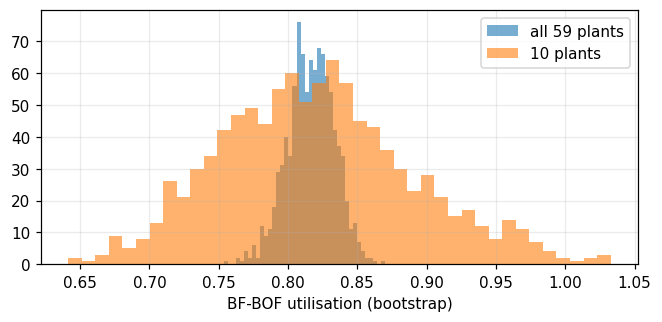

In [31]:
def boot_mean_u(df, n=1000, seed=SEED):
    """n bootstrap values of sum(production) / sum(capacity), resampling plants with replacement."""
    per_plant = df.groupby("Plant ID")[["Production_ttpa", CAP]].sum()
    prod, capa = per_plant["Production_ttpa"].to_numpy(), per_plant[CAP].to_numpy()
    n_plants = len(per_plant)
    idx = np.random.default_rng(seed).integers(0, n_plants, size=(n, n_plants))
    return prod[idx].sum(1) / capa[idx].sum(1)


bf_obs = obs_matched[obs_matched["Technology_type"] == "BF-BOF"]
bf_plants = bf_obs["Plant ID"].unique()

boot_all = boot_mean_u(bf_obs)
ci_all = np.percentile(boot_all, [5, 95])

small_ids = np.random.default_rng(SEED).choice(bf_plants, size=10, replace=False)
bf_small = bf_obs[bf_obs["Plant ID"].isin(small_ids)]
boot_small = boot_mean_u(bf_small)
ci_small = np.percentile(boot_small, [5, 95])

point_all = bf_obs["Production_ttpa"].sum() / bf_obs[CAP].sum()
point_small = bf_small["Production_ttpa"].sum() / bf_small[CAP].sum()
print(f"all BF-BOF plants ({len(bf_plants)}): point {point_all:.3f}, 90% CI {ci_all.round(3)}, width {np.diff(ci_all)[0]:.3f}")
print(f"10 BF-BOF plants        : point {point_small:.3f}, 90% CI {ci_small.round(3)}, width {np.diff(ci_small)[0]:.3f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(boot_all, bins=40, alpha=0.6, label=f"all {len(bf_plants)} plants")
ax.hist(boot_small, bins=40, alpha=0.6, label="10 plants")
ax.set_xlabel("BF-BOF utilisation (bootstrap)")
ax.legend()
plt.show()

### Q7 [QUANT + QUAL] Small sample, wide interval

(a) Report `ci_all` and `ci_small` and their widths. (b) Why is the second wider? (c) In one sentence, what does "90% interval" mean here? (d) Which kind of uncertainty (A or E) shrinks when you have more plants?

**Your answer (Q7):**

(a) **`ci_all`** (59 BF-BOF plants) = **[0.789, 0.842]**, width **0.053**; **`ci_small`** (10 plants) = **[0.714, 0.946]**, width **0.232**, about 4.4 times wider. The point estimates are almost the same (0.816 vs 0.815).

(b) With only 10 plants each resample can be dominated by a few unusually high- or low-utilisation plants. The average of a small sample moves much more from one sample to another (the spread shrinks roughly like 1/√n).

(c) If we repeated the sampling of plants many times and built the interval the same way each time, about 90% of those intervals would contain the true average utilisation of the population that these plants come from (here: Chinese BF-BOF plants that report production), *provided the sample is representative*.

(d) **Epistemic** uncertainty shrinks: it is our lack of knowledge about the average, and more plants reduce it. The aleatoric plant-to-plant and year-to-year variation does not go away with more data.

> ### [OPTIONAL] Bayesian version of the same interval
>
> A **credible interval** answers a more direct question: *given the data and what I believed before, where is the true average?* We start from a **prior guess** (mean $\mu_0$, worth $\kappa_0$ observations) and update it with the data (mean $\bar x$, $n$ observations):
>
> posterior mean $=\dfrac{\kappa_0\,\mu_0 + n\,\bar x}{\kappa_0+n}$ (a weighted average: the prior counts as $\kappa_0$ observations).
>
> **Task.** For the **10 plants** of `ci_small`, compute the posterior mean for (i) a **weak** prior ($\mu_0=0.5$, $\kappa_0=0.01$) and (ii) a **wrong** prior ($\mu_0=0.3$, $\kappa_0=5$). The width of a 90% interval is roughly $1.8\times s/\sqrt{n+\kappa_0}$ ($s$ = standard deviation of the 10 values).
> **Question Q7b.** How much does the wrong prior move the answer, and why does this matter when data are scarce?

In [32]:
# Plant-level utilisation of the 10 plants (pooled over their observed years)
small_u = bf_small.groupby("Plant ID")[["Production_ttpa", CAP]].sum()
small_u = small_u["Production_ttpa"] / small_u[CAP]
n_s, xbar, s = len(small_u), small_u.mean(), small_u.std(ddof=1)
print(f"n = {n_s}, mean = {xbar:.3f}, sd = {s:.3f}")

for name, mu0, k0 in [("weak prior", 0.5, 0.01), ("wrong prior", 0.3, 5)]:
    post = (k0 * mu0 + n_s * xbar) / (k0 + n_s)
    half = 0.9 * s / np.sqrt(n_s + k0)  # width ~ 1.8 s / sqrt(n + k0)
    print(f"{name:12s}: posterior mean {post:.3f}, ~90% interval [{post - half:.3f}, {post + half:.3f}], shift vs data {post - xbar:+.3f}")

n = 10, mean = 0.872, sd = 0.294
weak prior  : posterior mean 0.872, ~90% interval [0.788, 0.955], shift vs data -0.000
wrong prior : posterior mean 0.681, ~90% interval [0.613, 0.750], shift vs data -0.191


**Your answer (Q7b (optional)):**

The 10 plants have a mean plant utilisation of 0.872 (sd 0.294). With the **weak prior** (μ0 = 0.5, κ0 = 0.01) the posterior mean is **0.872**, i.e. the data alone, with an interval of about [0.79, 0.96]. With the **wrong prior** (μ0 = 0.3, κ0 = 5) it drops to **0.681**, a shift of **-0.19**: the prior counts as 5 observations against 10 real ones, so it carries a third of the weight. The interval also looks *narrower* ([0.61, 0.75]), which suggests false confidence. When data are scarce the prior can drive the answer, so it must be justified and tested for sensitivity; with 59 plants the same prior would move the mean much less.

## B4. Simulation: a range for emissions

**Idea (Monte Carlo).** Instead of one value per input, use a *plausible range*, then **repeat the whole calculation many times**, each time with different plausible values. The cloud of results shows the uncertainty of the output.

Two uncertain inputs:

| Input | Plausible range | How to draw |
|---|---|---|
| **Utilisation** per technology | the bootstrap values of B3 | one bootstrap value per draw and technology (all technologies pooled if a technology has fewer than 5 plants) |
| **Emission factor** per technology | multiplier on your Part A factor, **assumed illustrative values** below | triangular distribution (low, mode = 1, high): `rng.triangular(low, 1, high, size=n)` |

| Technology | low | mode | high |
|---|---|---|---|
| BF-BOF | 0.85 | 1 | 1.20 |
| EAF | 0.65 | 1 | 2.00 |
| Other | 0.65 | 1 | 1.40 |

**Goal.** Create `ef_mult_ranges` (dict) and a function `simulate(n=1000, year=2030, vary_util=True, vary_ef=True, bf_cap_mult=1.0, util_mult=1.0, seed=0)` returning a dict with
* `national`: array of `n` national emissions (**MtCO2**) for `year`;
* `national_prod`: array of `n` national productions (**Mt**);
* `by_company`: DataFrame (`n` rows, one column per company, MtCO2).

> **Hint.**
> 1. Take the rows of `china_operational` for `year`. For every plant you need: capacity (missing = 0), technology, your Part A emission factor, company.
> 2. Draw a matrix `u` (n x 3) of utilisations and a matrix `mult` (n x 3) of multipliers (columns = BF-BOF, EAF, Other). If `vary_util=False`, use the pooled matched utilisation of each technology instead (sum of production / sum of capacity over all years); if `vary_ef=False`, use multipliers equal to 1.
> 3. Choose each plant's column by its technology: `u[:, tech_index_of_plant]` gives an (n x plants) matrix. Then production = capacity x utilisation (x `util_mult`), emissions = production x 1,000 x factor x multiplier / 1e6.
> 4. `bf_cap_mult` multiplies the capacity of BF-BOF plants (used for scenarios later).
> 5. Company totals: `pd.DataFrame(em_matrix, columns=company_of_each_plant).T.groupby(level=0).sum().T`.

In [33]:
ef_mult_ranges = {"BF-BOF": (0.85, 1.0, 1.20), "EAF": (0.65, 1.0, 2.00), "Other": (0.65, 1.0, 1.40)}

# Utilisation draws per technology (bootstrap of B3); pooled over all technologies if fewer than 5 plants
n_plants_tech = obs_matched.groupby("Technology_type")["Plant ID"].nunique().reindex(TECHS, fill_value=0)
boot_by_tech, pooled_u = {}, {}
for t in TECHS:
    d = obs_matched[obs_matched["Technology_type"] == t] if n_plants_tech[t] >= 5 else obs_matched
    boot_by_tech[t] = boot_mean_u(d)
    pooled_u[t] = d["Production_ttpa"].sum() / d[CAP].sum()
print("plants per technology:", n_plants_tech.to_dict())
print("pooled matched utilisation:", {k: round(v, 3) for k, v in pooled_u.items()})


def simulate(n=1000, year=2030, vary_util=True, vary_ef=True, bf_cap_mult=1.0, util_mult=1.0, seed=0):
    rng = np.random.default_rng(seed)
    p = china_operational[china_operational["Year"] == year]
    capa = p[CAP].fillna(0).to_numpy() * np.where(p["Technology_type"] == "BF-BOF", bf_cap_mult, 1.0)
    tech_idx = p["Technology_type"].map({t: i for i, t in enumerate(TECHS)}).to_numpy()
    ef = p["Emission_factor_tCO2_per_t"].to_numpy()

    if vary_util:
        u = np.column_stack([rng.choice(boot_by_tech[t], size=n) for t in TECHS])
    else:
        u = np.tile([pooled_u[t] for t in TECHS], (n, 1))
    if vary_ef:
        mult = np.column_stack([rng.triangular(*ef_mult_ranges[t], size=n) for t in TECHS])
    else:
        mult = np.ones((n, len(TECHS)))

    prod = capa * u[:, tech_idx] * util_mult           # n x plants, ttpa
    em = prod * 1_000 * ef * mult[:, tech_idx] / 1e6   # n x plants, MtCO2
    by_company = pd.DataFrame(em, columns=p["Company"].to_numpy()).T.groupby(level=0).sum().T
    return {"national": em.sum(1), "national_prod": prod.sum(1) / 1_000, "by_company": by_company}


def summary(x):
    lo, med, hi = np.percentile(x, [5, 50, 95])
    return {"median": med, "p5": lo, "p95": hi, "rel_half_width": (hi - lo) / (2 * med)}


pd.DataFrame([summary(simulate(200)["national"])], index=["quick test 2030 (n=200)"])

plants per technology: {'BF-BOF': 59, 'EAF': 7, 'Other': 0}
pooled matched utilisation: {'BF-BOF': np.float64(0.816), 'EAF': np.float64(0.705), 'Other': np.float64(0.813)}


,median,p5,p95,rel_half_width
quick test 2030 (n=200),"1,936.77","1,740.03","2,168.79",0.11


### Q8 [QUANT + QUAL] Read the result

(a) For **2030**, report the **median** and the **90% interval** (5th to 95th percentile) of national emissions, and the **relative half-width** = (upper - lower) / (2 x median). (b) Compare the median with your **Part A value for 2030** (sum of `company_emissions` for 2030, in Mt). Which one is closer to the simulation, and why do they differ so much (hint: B1)?

2030 national emissions: median 1,905 MtCO2, 90% interval [1,696, 2,153], relative half-width 12.0%
Part A value for 2030: 151 MtCO2 (ratio simulation median / Part A = 12.6x)
2030 national production: median 1,022 Mt


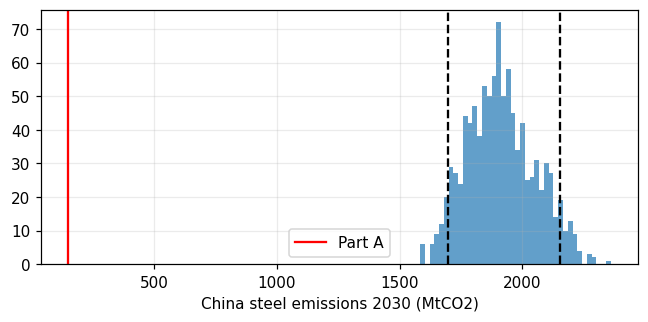

In [34]:
res_2030 = simulate(1000, year=2030)
q8 = summary(res_2030["national"])
partA_2030 = company_emissions.loc[company_emissions["Year"] == 2030, "estimated_emissions_tCO2"].sum() / 1e6

print(f"2030 national emissions: median {q8['median']:,.0f} MtCO2, 90% interval [{q8['p5']:,.0f}, {q8['p95']:,.0f}], "
      f"relative half-width {q8['rel_half_width']:.1%}")
print(f"Part A value for 2030: {partA_2030:,.0f} MtCO2 (ratio simulation median / Part A = {q8['median'] / partA_2030:.1f}x)")
print(f"2030 national production: median {np.median(res_2030['national_prod']):,.0f} Mt")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(res_2030["national"], bins=40, alpha=0.7)
ax.axvline(q8["p5"], ls="--", c="k"); ax.axvline(q8["p95"], ls="--", c="k")
ax.axvline(partA_2030, c="r", label="Part A")
ax.set_xlabel("China steel emissions 2030 (MtCO2)")
ax.legend()
plt.show()

**Your answer (Q8):**

(a) 2030 national emissions: **median ≈ 1,905 MtCO2**, **90% interval ≈ [1,696, 2,153] MtCO2**, relative half-width = (2,153 - 1,696) / (2 × 1,905) ≈ **12%**.

(b) The **Part A value for 2030 is only 151 MtCO2**, about **12.6 times smaller** than the simulation median, and it lies far outside the simulated range. The simulation is the realistic one: it implies about 1,020 Mt of steel, in line with official production, and roughly 1.9 GtCO2 is the right order of magnitude for Chinese steel. The gap comes from B1: Part A's utilisation divides the production of the ~10% of output that is reported by **all** capacity, so it is about 10 times too low. The simulation uses the matched utilisation (~0.8), where numerator and denominator describe the same plants.

### Q9 [QUANT + QUAL] Which input matters most?

Run `simulate` twice: once varying **only the utilisation** (`vary_ef=False`) and once varying **only the emission factor** (`vary_util=False`). For each, give the relative half-width for 2030. Which input creates more of the uncertainty? Could **more data** reduce it?

In [35]:
only_util = summary(simulate(1000, 2030, vary_ef=False)["national"])
only_ef = summary(simulate(1000, 2030, vary_util=False)["national"])
pd.DataFrame({"both": q8, "only utilisation": only_util, "only emission factor": only_ef}).T

,median,p5,p95,rel_half_width
both,"1,904.82","1,696.15","2,153.28",0.12
only utilisation,"1,878.36","1,820.58","1,936.77",0.03
only emission factor,"1,920.74","1,715.47","2,140.68",0.11


**Your answer (Q9):**

| Simulation | Relative half-width (2030) |
|---|---|
| Only utilisation varies (`vary_ef=False`) | **≈ 3.1%** |
| Only emission factor varies (`vary_util=False`) | **≈ 11.1%** |
| Both | ≈ 12.0% |

The **emission factor** creates most of the uncertainty. It is **epistemic**, so more data *could* reduce it: plant-level measured or reported CO2 intensities, the actual process routes (scrap share, PCI, CCS) and better equipment data. The utilisation range is narrow partly because it only reflects the *sampling* error of 59 BF-BOF plants pooled over several years, not the year-to-year (aleatoric) swings or the selection bias from Q6. It is therefore probably understated.

### Q10 [QUANT + QUAL] Companies: can you say who is number one?

Using `by_company` of your 2030 run: (a) for the **top 3 companies by median**, give the median and the 90% interval; (b) compute the probability that the #1 company emits **more than** the #2 (fraction of simulations); (c) what would you write in a report instead of "Company X is the largest emitter"?

In [36]:
bc = res_2030["by_company"]
top3 = bc.median().nlargest(3).index
q10 = pd.DataFrame({c: summary(bc[c]) for c in top3}).T
with pd.option_context("display.max_colwidth", 120):
    display(q10)

first, second = top3[0], top3[1]
p_first_gt_second = (bc[first] > bc[second]).mean()
print(f"P(#1 > #2) = {p_first_gt_second:.3f}")

# Rank of the median #1 across simulations
rank1 = bc.rank(axis=1, ascending=False)[first]
print("rank distribution of the median #1:", rank1.value_counts(normalize=True).sort_index().round(3).to_dict())

,median,p5,p95,rel_half_width
Angang Steel Co Ltd [100.0%],56.85,50.54,64.63,0.12
Baoshan Iron & Steel Co Ltd [100.0%],53.59,47.64,60.92,0.12
Beijing Shougang Co Ltd [100.0%],37.65,33.52,42.68,0.12


P(#1 > #2) = 1.000
rank distribution of the median #1: {1.0: 1.0}


**Your answer (Q10):**

(a) Top 3 by median (2030, MtCO2):

| Company | median | 90% interval |
|---|---|---|
| Angang Steel Co Ltd [100%] | 56.9 | [50.5, 64.6] |
| Baoshan Iron & Steel Co Ltd [100%] | 53.6 | [47.6, 60.9] |
| Beijing Shougang Co Ltd [100%] | 37.7 | [33.5, 42.7] |

(b) P(#1 > #2) = **1.00**: Angang is above Baoshan in every simulation, even though their intervals overlap almost completely. This is an **artefact of the model**: each draw applies the *same* utilisation and emission-factor multiplier to every BF-BOF plant, so all BF-BOF companies move up and down together and their ranking is fixed by capacity × factor. In reality plants vary independently, and the 6% gap between the two would not be robust. Ownership adds further uncertainty: Baoshan is part of China Baowu, which as a group would rank first.

(c) Instead of "Company X is the largest emitter", I would write: *"Angang Steel and Baoshan Iron & Steel are estimated to be the two largest emitters in our plant sample, each around 50-65 MtCO2 in 2030; their estimates are too close and too uncertain to rank one above the other, and at group level (e.g. China Baowu) the ranking may differ."*

## B5. Is the interval honest? Test it

A 90% interval should contain the true value in about 90% of cases. We have one case where the truth is known: **official 2023 production**.

### Q11 [QUANT + QUAL] Does the official value fall inside?

Run `simulate(1000, year=2023)` and look at `national_prod` (Mt). (a) Give its 90% interval and say whether the official 2023 value (1,020 Mt) falls inside. (b) If not, what does this tell you about the interval, **even though it was computed correctly**? (c) What would you do about it?

In [37]:
res_2023 = simulate(1000, year=2023)
prod_2023 = summary(res_2023["national_prod"])
print(f"2023 production: median {prod_2023['median']:,.0f} Mt, 90% interval [{prod_2023['p5']:,.0f}, {prod_2023['p95']:,.0f}] Mt")
print("official 2023 (1,020 Mt) inside the interval:", prod_2023["p5"] <= 1020 <= prod_2023["p95"])
print(f"capacity counted in 2023: {china_capacity[2023] / 1000:,.0f} Mt")

# One check is weak evidence: repeat it for every year with an official value
calib = pd.DataFrame({y: summary(simulate(1000, year=y)["national_prod"]) for y in official_kt}).T
calib["official_Mt"] = pd.Series(official_kt) / 1000
calib["inside"] = (calib["p5"] <= calib["official_Mt"]) & (calib["official_Mt"] <= calib["p95"])
calib

2023 production: median 1,031 Mt, 90% interval [992, 1,066] Mt
official 2023 (1,020 Mt) inside the interval: True
capacity counted in 2023: 1,288 Mt


,median,p5,p95,rel_half_width,official_Mt,inside
2020,"1,074.56","1,035.03","1,109.47",0.03,"1,065.00",True
2021,"1,071.15","1,032.12","1,106.69",0.03,"1,035.00",True
2022,"1,059.17","1,020.44","1,094.40",0.03,"1,015.00",False
2023,"1,030.83",991.68,"1,065.98",0.04,"1,020.00",True


**Your answer (Q11):**

(a) Simulated 2023 production: **median ≈ 1,031 Mt, 90% interval ≈ [992, 1,066] Mt**. The official value of **1,020 Mt falls inside**. Repeating the check for every year with an official value, the interval contains the official figure in 2020, 2021 and 2023 but **not in 2022** (official 1,015 Mt vs [1,020, 1,094] Mt): 3 out of 4 years.

(b) An interval can be computed correctly and still be **over-confident**. It only covers the uncertainty we put into the model (the sampling of reporting plants and the emission factors), and its half-width is only ±3-4% for production. It ignores errors in the *capacity* (Q1: ~15-24% non-operating lines counted as operating, small plants below GEM's threshold missing), selection bias in the reporting plants, and year-to-year shocks. The good 2023 result is also partly luck: too much retired capacity and too few small plants roughly **cancel out**. One year inside the interval does not prove that the interval is calibrated, and missing 1 year in 4 is more than the 10% a true 90% interval would allow.

(c) Back-test the interval on every year available (as done above) and **widen it** until it covers the official values about 90% of the time. Better still, add the missing sources of uncertainty: a capacity / status uncertainty (filter or weight non-operating lines), a coverage term, and year-to-year utilisation variation instead of one pooled rate.

## B6. Scenarios

A **scenario** is a "what if" story. We do **not** attach a probability to it; we run each one through the same simulation and compare.

| Scenario | Story | How |
|---|---|---|
| **S0** | no change | as is |
| **S1** | **30% of BF-BOF capacity is retired** (by 2027, still true in 2030) | `bf_cap_mult=0.7` |
| **S2** | **steel demand drops**: utilisation 10% lower | `util_mult=0.9` |

### Q12 [QUANT + QUAL] Scenario gap vs interval width

(a) Run the three scenarios for 2030 and give the **median and 90% interval** of each. (b) Compare the **gap between** scenario medians with the **width of the interval** within a scenario. Which is bigger? (c) Why would it be misleading to average the three scenarios into one probability-weighted number?

,median,p5,p95,rel_half_width,interval_width,gap_vs_S0_median
S0 no change,"1,904.82","1,696.15","2,153.28",0.12,457.13,0.00
S1 30% BF-BOF retired,"1,351.79","1,205.12","1,527.62",0.12,322.51,-553.03
S2 demand -10%,"1,714.34","1,526.53","1,937.95",0.12,411.42,-190.48


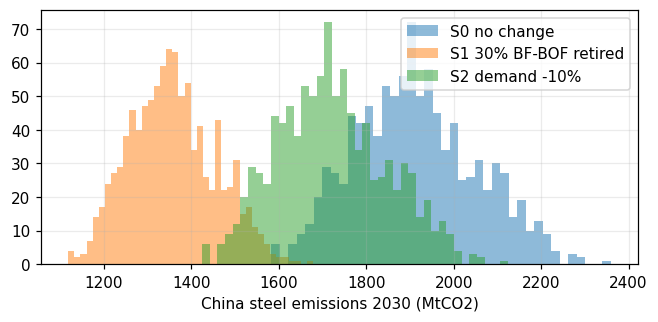

In [38]:
scenarios = {
    "S0 no change": dict(),
    "S1 30% BF-BOF retired": dict(bf_cap_mult=0.7),
    "S2 demand -10%": dict(util_mult=0.9),
}
scen_res = {k: simulate(1000, 2030, **kw) for k, kw in scenarios.items()}
q12 = pd.DataFrame({k: summary(r["national"]) for k, r in scen_res.items()}).T
q12["interval_width"] = q12["p95"] - q12["p5"]
q12["gap_vs_S0_median"] = q12["median"] - q12.loc["S0 no change", "median"]
display(q12)

fig, ax = plt.subplots(figsize=(7, 3))
for k, r in scen_res.items():
    ax.hist(r["national"], bins=40, alpha=0.5, label=k)
ax.set_xlabel("China steel emissions 2030 (MtCO2)")
ax.legend()
plt.show()

**Your answer (Q12):**

(a) 2030 national emissions (MtCO2):

| Scenario | median | 90% interval | width |
|---|---|---|---|
| S0 no change | 1,905 | [1,696, 2,153] | 457 |
| S1 30% of BF-BOF retired | 1,352 | [1,205, 1,528] | 323 |
| S2 utilisation -10% | 1,714 | [1,527, 1,938] | 411 |

(b) **The gap between S0 and S1 (≈ 553 Mt) is larger than the interval width within a scenario (≈ 320-460 Mt)**: the S0 and S1 intervals do not even overlap. The gap between S0 and S2 (≈ 190 Mt) is smaller than the width, so S2's effect is within the model uncertainty. Policy choices on capacity matter at least as much as our parameter uncertainty, so the scenario question is the first-order one.

(c) Scenarios are "what if" stories with **no known probability**. Averaging them requires inventing weights, which turns a policy choice into a fake probability. The result also corresponds to **no possible world** (no one retires "a weighted 10%" of capacity), and it **hides the spread** a risk committee needs to see: the S0 high case versus the S1 low case. Each scenario should be shown separately, as in a stress test.

## B7. Communicate

Words used by the IPCC for probabilities: **virtually certain** 99-100%, **very likely** 90-100%, **likely** 66-100%, **about as likely as not** 33-66%, **unlikely** 10-33%, **very unlikely** 1-10%, **exceptionally unlikely** 0-1%.

### Q13 [QUANT + QUAL] A probability, a word, and a note

(a) For each scenario, compute the probability that **2030 emissions exceed the 2023 median** (from your `simulate(..., year=2023)`) and give the matching word. (b) Write a note of **about 80 words** for a bank's risk committee about China's steel emissions in 2030. Include: the **median and 90% interval** (baseline), **one sentence on the scenarios**, the **biggest source of uncertainty**, **one limitation** of the model and **one recommended action**. Plain language, no jargon.

> **Hint.** `(draws > threshold).mean()`.

In [39]:
threshold = np.median(res_2023["national"])
print(f"2023 median emissions: {threshold:,.0f} MtCO2")


def ipcc_word(p):
    if p >= 0.99: return "virtually certain"
    if p >= 0.90: return "very likely"
    if p >= 0.66: return "likely"
    if p >= 0.33: return "about as likely as not"
    if p >= 0.10: return "unlikely"
    if p >= 0.01: return "very unlikely"
    return "exceptionally unlikely"


q13 = pd.DataFrame({k: {"P(2030 > 2023 median)": (r["national"] > threshold).mean()} for k, r in scen_res.items()}).T
q13["IPCC word"] = q13["P(2030 > 2023 median)"].map(ipcc_word)
q13

2023 median emissions: 1,925 MtCO2


,P(2030 > 2023 median),IPCC word
S0 no change,0.43,about as likely as not
S1 30% BF-BOF retired,0.00,exceptionally unlikely
S2 demand -10%,0.06,very unlikely


**Your answer (Q13):**

(a) Threshold = median of simulated 2023 emissions ≈ **1,925 MtCO2**.

| Scenario | P(2030 emissions > 2023 median) | IPCC word |
|---|---|---|
| S0 no change | 0.43 | **about as likely as not** |
| S1 30% BF-BOF retired | 0.00 | **exceptionally unlikely** |
| S2 demand -10% | 0.06 | **very unlikely** |

(b) **Note to the risk committee (~80 words)**

If nothing changes, China's steel sector should emit about **1.9 billion tonnes of CO2 in 2030** (90% range: 1.7-2.15 billion), roughly today's level. Closing 30% of blast-furnace capacity would cut this by about 0.55 billion; a 10% fall in demand, by about 0.2 billion. The biggest uncertainty is how much CO2 each tonne of steel really emits. Limitation: few plants publish production, and ownership data are incomplete. Recommendation: collect plant-level emissions data from borrowers and stress-test the loan book under each scenario.